# Промежуточная аттестация 2 — анализ данных RFSD

**Данные:** [RFSD](https://github.com/irlcode/RFSD) — открытая база бухгалтерской отчётности российских компаний. Лежит на Hugging Face: `irlspbru/RFSD`.

**Что делаем:**
1. Берём данные за 2023 год. Весь датасет не скачиваем: Polars читает с сервера только нужные колонки и первые строки.
2. Оставляем 20 колонок и 1000 строк.
3. Смотрим общую статистику, строим гистограммы, ищем выбросы, считаем корреляции, рисуем диаграммы рассеивания и делаем выводы.

Все суммы в данных — **в тысячах рублей**.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

## 0. Загрузка данных

Берём 20 числовых колонок: размер компании, её имущество и долги, выручка и прибыль, а также возраст и координаты.

| Код в RFSD | Имя в ноутбуке | Что это |
|---|---|---|
| line_1100 | noncurrent_assets | Внеоборотные активы (то, что служит годами: здания, оборудование) |
| line_1150 | fixed_assets | Основные средства |
| line_1200 | current_assets | Оборотные активы (деньги, запасы, долги покупателей) |
| line_1210 | inventories | Запасы |
| line_1230 | receivables | Дебиторская задолженность (сколько должны компании) |
| line_1250 | cash | Деньги на счетах и в кассе |
| line_1300 | equity | Собственный капитал |
| line_1400 | lt_liabilities | Долгосрочные долги (больше года) |
| line_1500 | st_liabilities | Краткосрочные долги (до года) |
| line_1520 | payables | Кредиторская задолженность (сколько должна компания) |
| line_1600 | total_assets | Итог баланса (всё имущество компании) |
| line_2110 | revenue | Выручка |
| line_2120 | cost_of_sales | Себестоимость (записана со знаком «минус») |
| line_2200 | sales_profit | Прибыль от продаж |
| line_2300 | pretax_profit | Прибыль до налогов |
| line_2400 | net_profit | Чистая прибыль |
| age | age | Возраст компании, лет |
| lat, lon | lat, lon | Широта и долгота адреса |
| simplified | simplified | 1 — упрощённая отчётность (обычно малый бизнес) |

In [2]:
SOURCE = "hf://datasets/irlspbru/RFSD/RFSD/year=2023/part-0.parquet"

COLUMNS = {
    "line_1100": "noncurrent_assets",
    "line_1150": "fixed_assets",
    "line_1200": "current_assets",
    "line_1210": "inventories",
    "line_1230": "receivables",
    "line_1250": "cash",
    "line_1300": "equity",
    "line_1400": "lt_liabilities",
    "line_1500": "st_liabilities",
    "line_1520": "payables",
    "line_1600": "total_assets",
    "line_2110": "revenue",
    "line_2120": "cost_of_sales",
    "line_2200": "sales_profit",
    "line_2300": "pretax_profit",
    "line_2400": "net_profit",
    "age": "age",
    "lat": "lat",
    "lon": "lon",
    "simplified": "simplified",
}

# Lazy-скан: polars читает с Hugging Face только метаданные, выбранные колонки
# и столько row-group'ов, сколько нужно для первых 1000 строк.
df = (
    pl.scan_parquet(SOURCE)
    .select(list(COLUMNS))
    .head(1000)
    .collect()
    .rename(COLUMNS)
    .to_pandas()
)

print("Размер выборки:", df.shape)
df.head()

Размер выборки: (1000, 20)


,noncurrent_assets,fixed_assets,current_assets,inventories,receivables,cash,equity,lt_liabilities,st_liabilities,payables,total_assets,revenue,cost_of_sales,sales_profit,pretax_profit,net_profit,age,lat,lon,simplified
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,19.00,53.76,87.10,NaN
1,87.00,13.00,"4,280.00",NaN,"1,040.00","3,240.00","4,083.00",NaN,284.00,284.00,"4,367.00","3,734.00","-3,099.00",635.00,756.00,529.00,19.00,53.75,87.17,1.00
2,NaN,NaN,"3,069.00",220.00,"1,795.00","1,054.00",952.00,NaN,"2,117.00","2,117.00","3,069.00","10,193.00","-9,126.00","1,067.00","1,134.00",907.00,19.00,53.75,87.17,1.00
3,NaN,NaN,100.00,NaN,100.00,NaN,18.00,NaN,82.00,82.00,100.00,125.00,-121.00,4.00,4.00,11.00,19.00,53.76,87.12,0.00
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,19.00,53.76,87.17,NaN


## 1. Описательная статистика

In [3]:
desc = df.describe().T
desc["missing_%"] = df.isna().mean() * 100
desc["skew"] = df.skew()
desc

,count,mean,std,min,25%,50%,75%,max,missing_%,skew
noncurrent_assets,423.00,"209,788.99","2,201,531.01",0.00,0.00,680.00,"8,512.00","43,092,170.00",57.70,17.92
fixed_assets,359.00,"155,038.03","1,529,617.21",0.00,18.00,"1,242.00","10,549.50","27,924,620.00",64.10,17.00
current_assets,786.00,"181,653.53","1,873,488.34",0.00,151.50,"2,231.50","12,326.75","38,360,474.00",21.40,16.39
inventories,532.00,"65,697.45","655,916.55",-512.00,3.75,288.00,"4,015.00","12,743,257.00",46.80,16.02
receivables,694.00,"123,970.52","1,400,319.26",0.00,72.25,"1,045.50","8,244.25","31,445,705.00",30.60,18.55
cash,730.00,"10,520.51","107,937.86","-1,255.00",11.25,144.00,"1,007.50","2,218,132.00",27.00,17.55
equity,747.00,"89,894.44","873,923.59","-3,293,712.00",10.00,610.00,"7,090.00","16,083,322.00",25.30,12.85
lt_liabilities,313.00,"157,600.80","1,540,086.18",-16.00,0.00,580.00,"6,476.00","26,551,213.00",68.70,16.34
st_liabilities,705.00,"163,045.77","1,987,000.33",0.00,79.00,886.00,"7,854.00","46,355,797.00",29.50,19.92
payables,689.00,"86,365.97","788,944.69",0.00,56.00,601.00,"5,626.00","14,785,200.00",31.10,14.55


In [4]:
# Несколько «санитарных» проверок бухгалтерской логики
fin = df.dropna(subset=["total_assets"])
asset_gap = fin["total_assets"] - fin[["noncurrent_assets", "current_assets"]].fillna(0).sum(axis=1)
liab_gap = fin["total_assets"] - fin[["equity", "lt_liabilities", "st_liabilities"]].fillna(0).sum(axis=1)

checks = pd.Series({
    "Компаний без отчётности (total_assets = NaN)": df["total_assets"].isna().sum(),
    "Актив ≠ 1100 + 1200": (asset_gap.abs() > 1).sum(),
    "Пассив ≠ 1300 + 1400 + 1500": (liab_gap.abs() > 1).sum(),
    "Отрицательный капитал (equity < 0)": (df["equity"] < 0).sum(),
    "Нулевая выручка": (df["revenue"] == 0).sum(),
    "Отрицательные денежные средства (cash < 0)": (df["cash"] < 0).sum(),
    "Отрицательные долгоср. обязательства": (df["lt_liabilities"] < 0).sum(),
    "Убыток (net_profit < 0)": (df["net_profit"] < 0).sum(),
    "Прибыль (net_profit > 0)": (df["net_profit"] > 0).sum(),
})
checks.to_frame("кол-во")

,кол-во
Компаний без отчётности (total_assets = NaN),174
Актив ≠ 1100 + 1200,0
Пассив ≠ 1300 + 1400 + 1500,46
Отрицательный капитал (equity < 0),85
Нулевая выручка,54
Отрицательные денежные средства (cash < 0),2
Отрицательные долгоср. обязательства,1
Убыток (net_profit < 0),136
Прибыль (net_profit > 0),462


In [5]:
# Откуда эти 1000 компаний? Берём регион и возраст отдельным лёгким запросом — только для контекста,
# в анализируемые 20 колонок регион не входит.
meta = pl.scan_parquet(SOURCE).select(["region", "okved_section"]).head(1000).collect().to_pandas()
print(meta["region"].value_counts().head(6).to_string())
print()
print(pd.crosstab(df["age"], meta["region"]).loc[:, lambda t: t.sum() > 5])

region
kemerovo       844
bryansk         86
novosibirsk     32
moscow city      9
altai rep.       6
tomsk            5

region  altai rep.  bryansk  kemerovo  moscow city  novosibirsk
age                                                            
8.00             0       86         0            0            0
13.00            0        0       122            2            5
14.00            1        0       142            1           10
15.00            2        0       149            1            3
16.00            0        0       151            2            3
17.00            1        0       118            3            5
18.00            2        0       105            0            4
19.00            0        0        57            0            2


**Что видно из таблиц**

* **Среднее обманывает.** Типичная компания (медиана) получает около 6,6 млн ₽ выручки в год, а средняя выручка — 427 млн ₽. Среднее завышают несколько гигантов, самый крупный из которых зарабатывает 113 млрд ₽. Поэтому дальше смотрим в основном на медиану.
* **Много пустых ячеек.** 17 % компаний вообще не сдали отчёт за 2023 год. Малые фирмы сдают упрощённую отчётность и многие строки не заполняют, поэтому, например, у долгосрочных долгов пусто в 69 % случаев.
* **Есть невозможные значения.** Деньги (−1255), запасы (−512) и долгосрочные долги (−16) не могут быть отрицательными. Скорее всего, это ошибки при заполнении.
* **Есть тревожные значения.** У 85 компаний отрицательный капитал: долгов больше, чем всего имущества. У 54 компаний выручка ровно ноль: похоже, они не работают.
* **Баланс сходится не везде.** Должно быть «имущество = капитал + долги», но у 46 отчётов это не выполняется: часть строк не заполнена.
* **Выборка не случайная.** Файл отсортирован по ИНН, поэтому первые 1000 строк — в основном компании из Кемеровской области (84 %, в основном Новокузнецк) и немного из Брянской (9 %). Выводы касаются этих компаний, а не всей России.

## 2. Гистограммы и выбросы

Для гистограмм берём три главных показателя: **выручку**, **итог баланса** (сколько всего имущества) и **чистую прибыль**.

Разброс огромный: от нуля до сотен миллиардов рублей. В обычном масштабе почти все компании попадают в один столбик около нуля. Поэтому для каждого показателя строим два графика: в обычном масштабе (слева) и в логарифмическом (справа), где каждое деление по оси X означает «в 10 раз больше». Прибыль бывает отрицательной, поэтому для неё масштаб симметричный: убытки слева от нуля, прибыль справа.

**Как ищем выбросы:** берём средние 50 % компаний (от 25-го до 75-го процентиля). Выбросом считаем значение, которое отстоит от этой середины больше чем на полторы её ширины. Это стандартное правило 1,5·IQR.

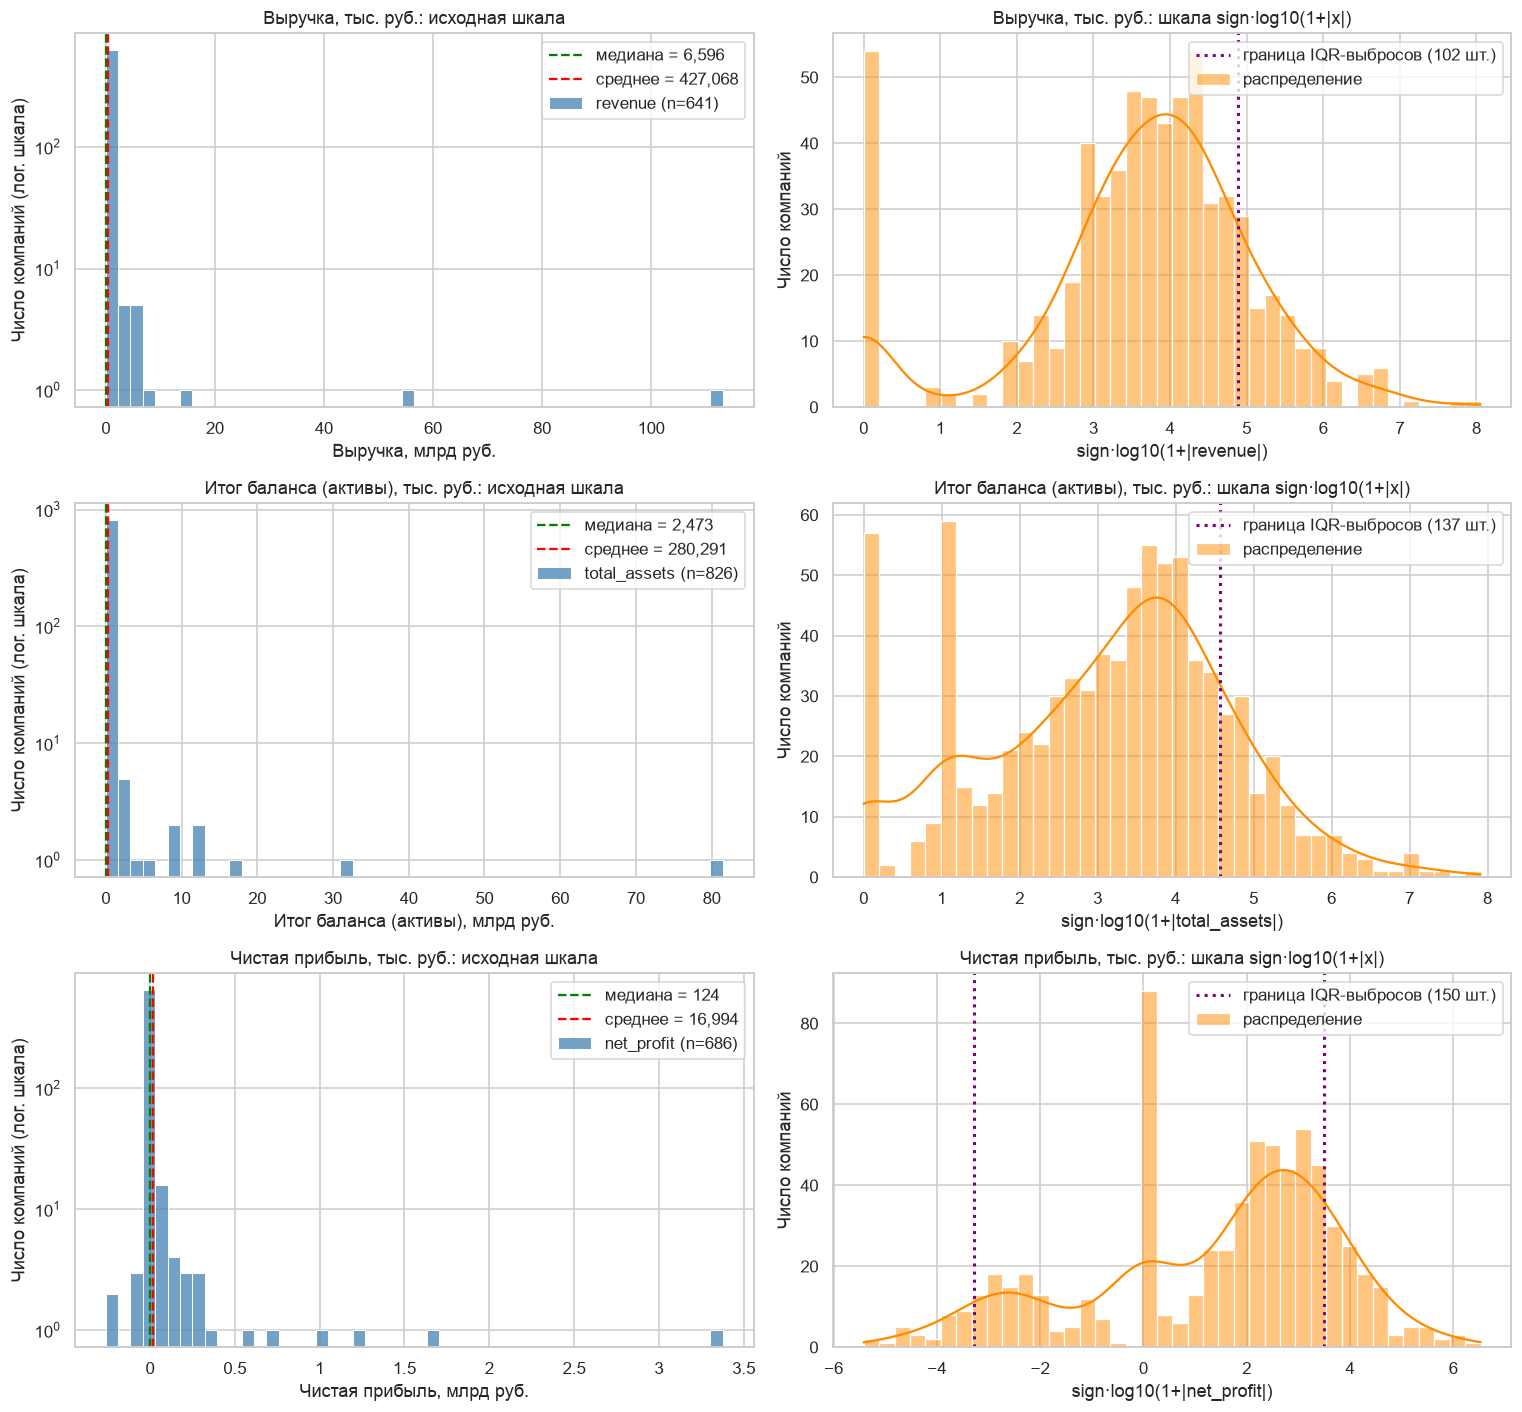

In [6]:
def iqr_outliers(s: pd.Series):
    s = s.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (s < lo) | (s > hi)
    return mask.sum(), lo, hi, s[mask]

def symlog(x):
    return np.sign(x) * np.log10(1 + np.abs(x))

HIST_COLS = {
    "revenue": "Выручка, тыс. руб.",
    "total_assets": "Итог баланса (активы), тыс. руб.",
    "net_profit": "Чистая прибыль, тыс. руб.",
}

fig, axes = plt.subplots(3, 2, figsize=(14, 13))
for row, (col, label) in enumerate(HIST_COLS.items()):
    s = df[col].dropna()
    n_out, lo, hi, _ = iqr_outliers(s)

    ax = axes[row, 0]
    sns.histplot(s, bins=50, ax=ax, color="steelblue", label=f"{col} (n={len(s)})")
    ax.axvline(s.median(), color="green", ls="--", label=f"медиана = {s.median():,.0f}")
    ax.axvline(s.mean(), color="red", ls="--", label=f"среднее = {s.mean():,.0f}")
    ax.set_yscale("log")
    ax.set_title(f"{label}: исходная шкала")
    ax.set_xlabel(label.replace("тыс. руб.", "млрд руб."))
    ax.set_ylabel("Число компаний (лог. шкала)")
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v/1e6:g}"))
    ax.legend()

    ax = axes[row, 1]
    t = symlog(s)
    sns.histplot(t, bins=40, ax=ax, color="darkorange", kde=True, label="распределение")
    ax.axvline(symlog(hi), color="purple", ls=":", lw=2, label=f"граница IQR-выбросов ({n_out} шт.)")
    if s.min() < lo:
        ax.axvline(symlog(lo), color="purple", ls=":", lw=2)
    ax.set_title(f"{label}: шкала sign·log10(1+|x|)")
    ax.set_xlabel(f"sign·log10(1+|{col}|)")
    ax.set_ylabel("Число компаний")
    ax.legend()

plt.tight_layout()
plt.show()

In [7]:
rows = []
for col in HIST_COLS:
    s = df[col].dropna()
    n_out, lo, hi, out = iqr_outliers(s)
    top5_share = s.nlargest(5).sum() / s.clip(lower=0).sum()
    rows.append({
        "колонка": col,
        "n": len(s),
        "медиана": s.median(),
        "среднее": s.mean(),
        "max": s.max(),
        "min": s.min(),
        "IQR-выбросов": n_out,
        "доля выбросов, %": 100 * n_out / len(s),
        "доля топ-5 в сумме, %": 100 * top5_share,
        "ровно 0, шт.": (s == 0).sum(),
    })
pd.DataFrame(rows).set_index("колонка")

,n,медиана,среднее,max,min,IQR-выбросов,"доля выбросов, %","доля топ-5 в сумме, %","ровно 0, шт."
колонка,,,,,,,,,
revenue,641,"6,596.00","427,068.49","113,115,306.00",0.00,102,15.91,71.89,54
total_assets,826,"2,473.00","280,291.06","81,452,644.00",0.00,137,16.59,67.29,57
net_profit,686,123.50,"16,993.63","3,375,980.00","-260,571.00",150,21.87,63.00,88


In [8]:
# Самая крупная компания выборки — она же главный «выброс»
giant = df.loc[df["revenue"].idxmax()]
giant[["revenue", "cost_of_sales", "sales_profit", "net_profit", "total_assets", "lt_liabilities", "age"]].to_frame("крупнейшая компания")

,крупнейшая компания
revenue,"113,115,306.00"
cost_of_sales,"-115,328,730.00"
sales_profit,"-17,837,340.00"
net_profit,"731,070.00"
total_assets,"81,452,644.00"
lt_liabilities,"26,551,213.00"
age,15.00


**Что видно на гистограммах**

* **Выручка.** У большинства компаний выручка от 1 до 100 млн ₽ в год (пик на правом графике около 10 млн ₽). Справа длинный «хвост» из нескольких очень крупных компаний: **5 крупнейших компаний дают 72 % выручки всей выборки.** Отдельный столбик в нуле — 54 компании без выручки, вероятно, неработающие.
* **Итог баланса.** Картина похожая: самая крупная компания (81 млрд ₽) в 33 000 раз больше типичной (2,5 млн ₽), а 5 крупнейших владеют 67 % всего имущества выборки. Есть два странных пика: ровно 0 (57 компаний) и около 10 тыс. ₽. 10 тыс. ₽ — минимальный уставный капитал ООО, то есть у таких компаний на балансе нет ничего, кроме денег, внесённых при регистрации.
* **Чистая прибыль.** На правом графике два «горба»: справа прибыльные компании (462), слева убыточные (136, примерно каждая пятая). Посередине высокий столбик — 88 компаний с прибылью ровно ноль. Прибыль варьируется от −260 млн ₽ до +3,4 млрд ₽.

**Вывод по выбросам:** почти все выбросы — настоящие крупные компании. Удалять их нельзя, но и считать по ним среднее бессмысленно: лучше смотреть на медиану или на логарифмический масштаб. Настоящие ошибки — отрицательные деньги, запасы и долги

## 3. Матрица корреляции 20 × 20

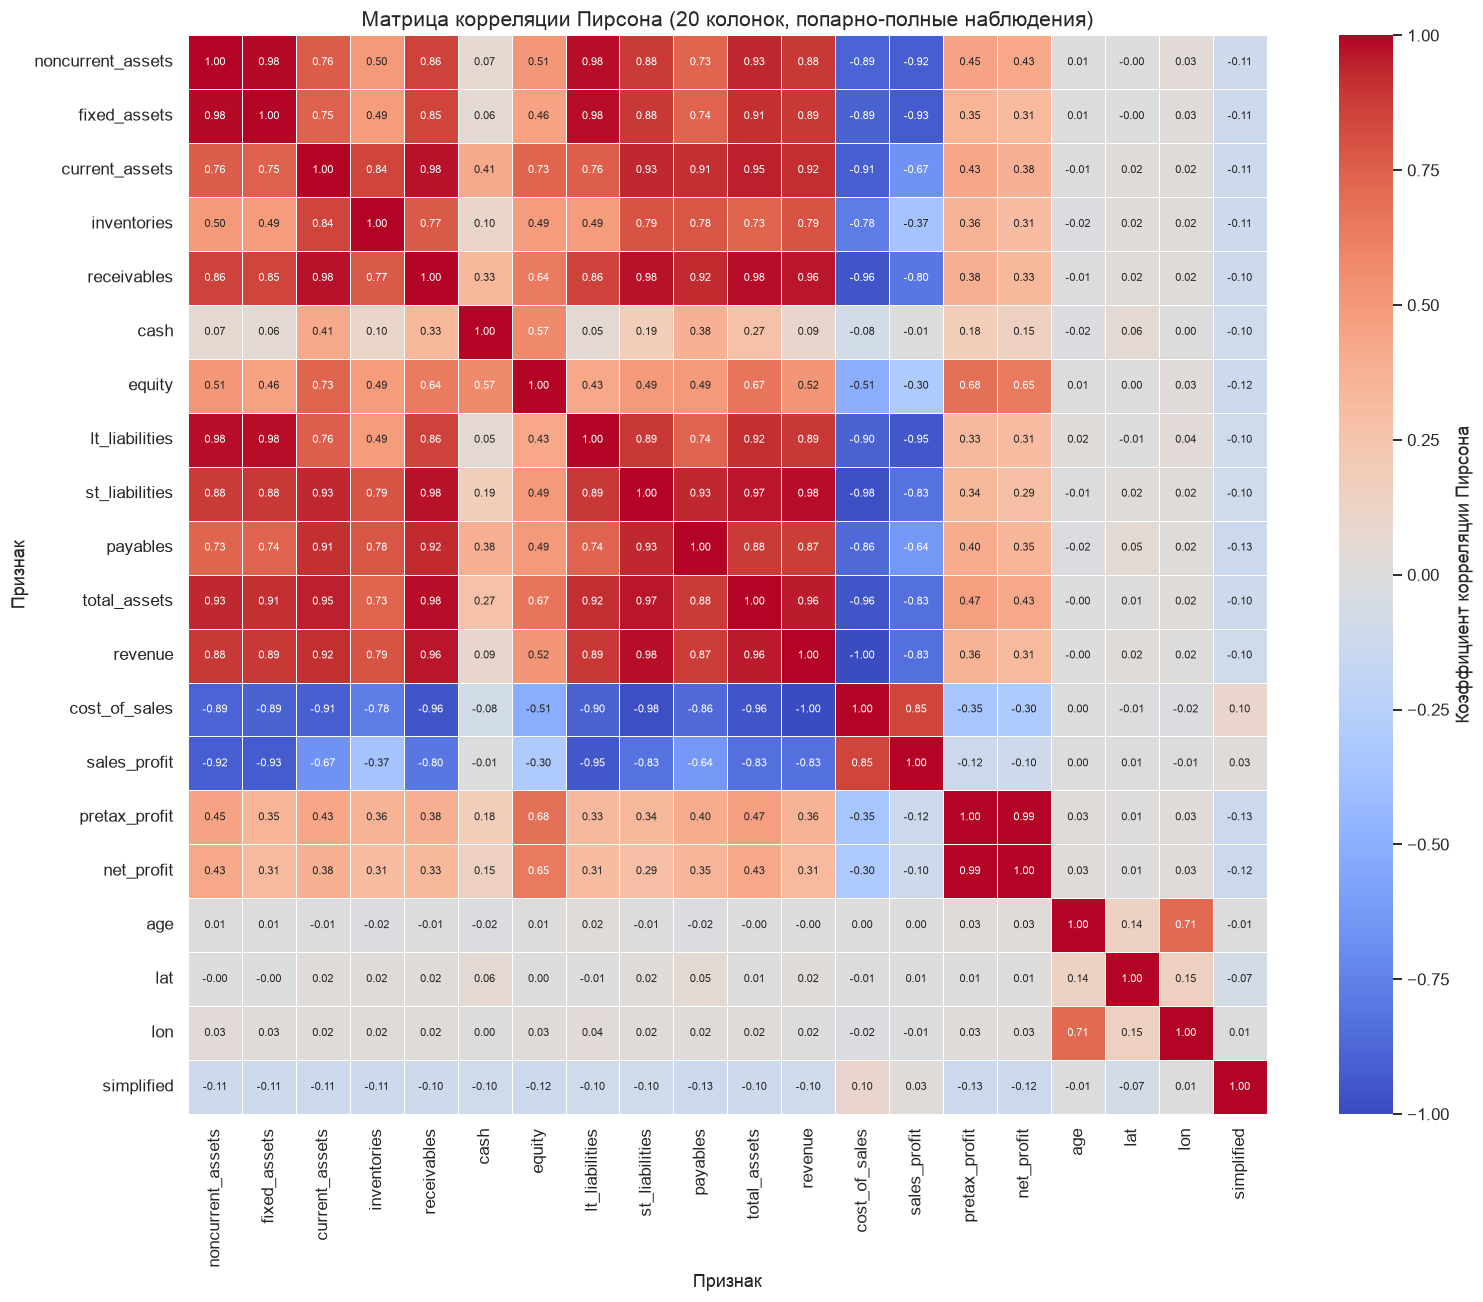

In [9]:
corr_p = df.corr(method="pearson")

fig, ax = plt.subplots(figsize=(15, 12))
sns.heatmap(
    corr_p, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0,
    square=True, linewidths=0.4, annot_kws={"size": 7},
    cbar_kws={"label": "Коэффициент корреляции Пирсона"}, ax=ax,
)
ax.set_title("Матрица корреляции Пирсона (20 колонок, попарно-полные наблюдения)", fontsize=14)
ax.set_xlabel("Признак")
ax.set_ylabel("Признак")
plt.tight_layout()
plt.show()

Обычная корреляция (Пирсона) очень чувствительна к выбросам: одна гигантская компания может её сильно исказить. Поэтому дополнительно считаем **корреляцию Спирмена**. Она сравнивает не сами числа, а места компаний в рейтинге («кто больше, кто меньше»), и выбросы на неё почти не влияют. Если два коэффициента сильно различаются, связь, скорее всего, создана выбросами.

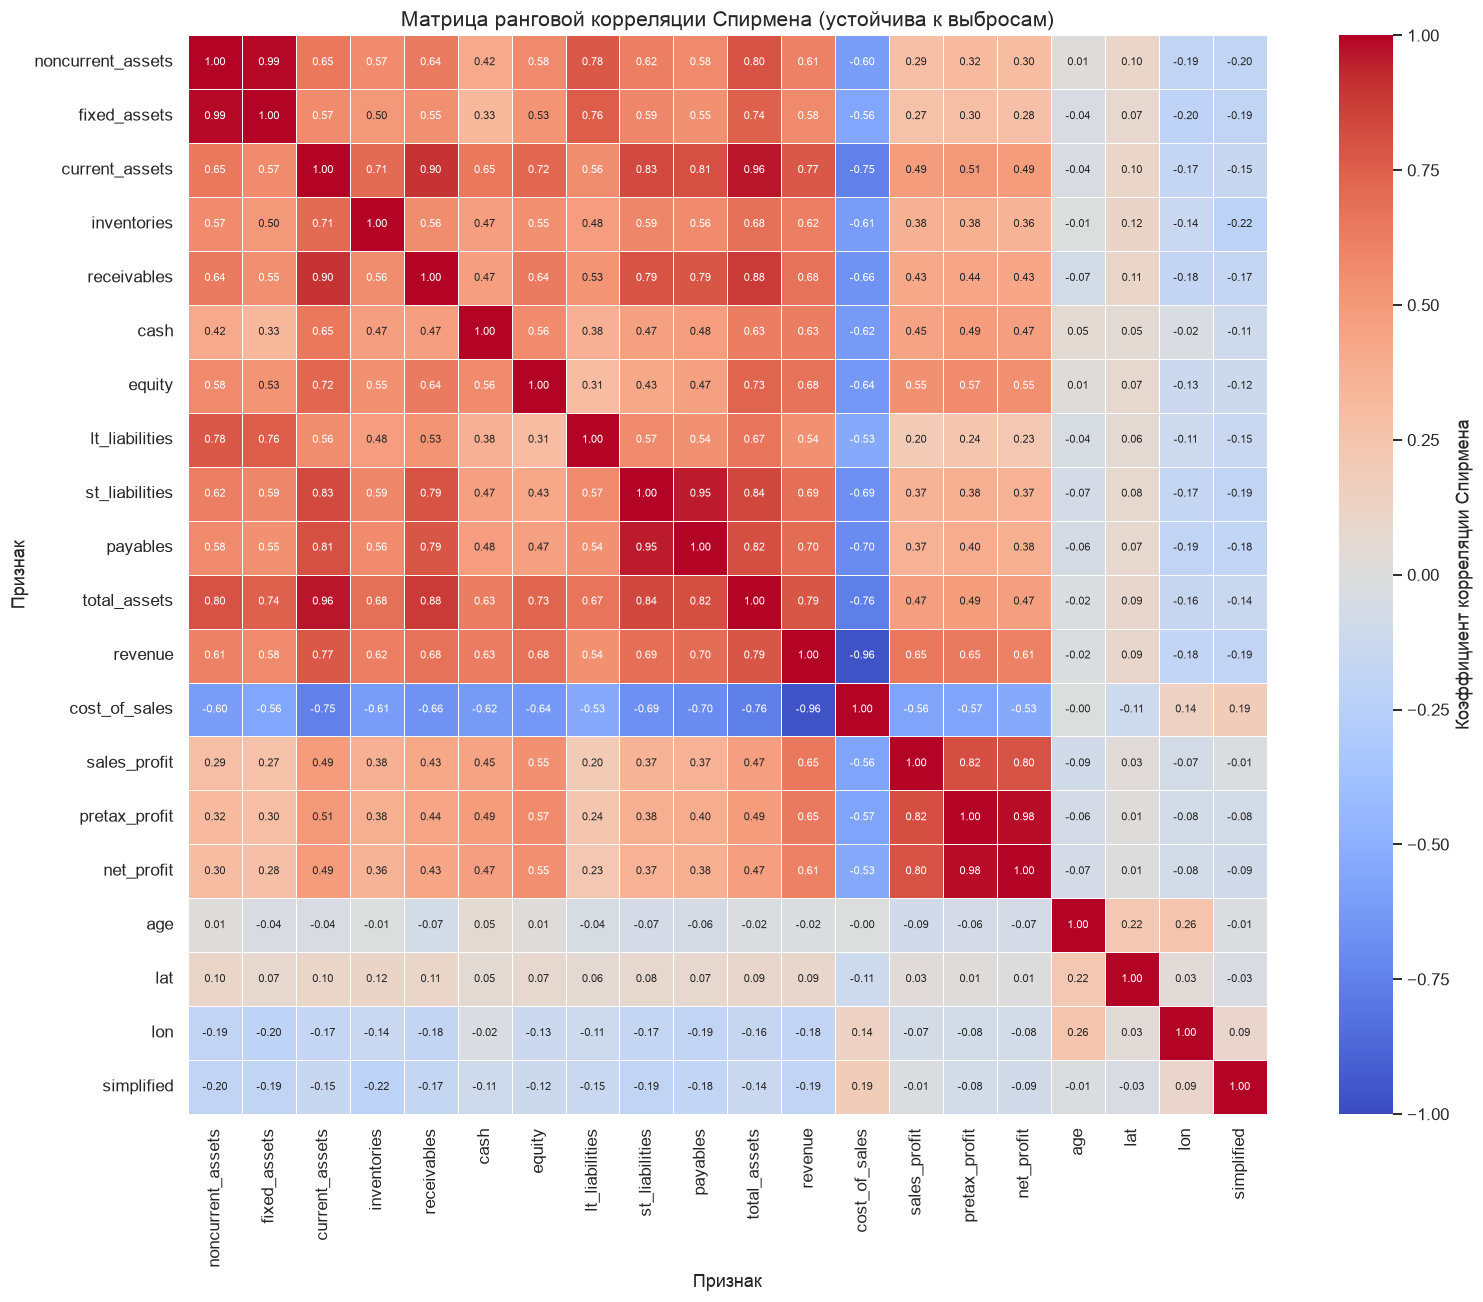

In [10]:
corr_s = df.corr(method="spearman")

fig, ax = plt.subplots(figsize=(15, 12))
sns.heatmap(
    corr_s, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0,
    square=True, linewidths=0.4, annot_kws={"size": 7},
    cbar_kws={"label": "Коэффициент корреляции Спирмена"}, ax=ax,
)
ax.set_title("Матрица ранговой корреляции Спирмена (устойчива к выбросам)", fontsize=14)
ax.set_xlabel("Признак")
ax.set_ylabel("Признак")
plt.tight_layout()
plt.show()

In [11]:
cols = corr_p.columns
pairs = pd.DataFrame(
    [(a, b, corr_p.loc[a, b], corr_s.loc[a, b])
     for i, a in enumerate(cols) for b in cols[i + 1:]],
    columns=["признак 1", "признак 2", "pearson", "spearman"],
)
pairs["|pearson - spearman|"] = (pairs["pearson"] - pairs["spearman"]).abs()

print("Пары с |r Пирсона| > 0.9:")
display(pairs[pairs["pearson"].abs() > 0.9].sort_values("pearson", key=abs, ascending=False).head(15))

print("Пары, где Пирсон и Спирмен расходятся сильнее всего (эффект выбросов):")
display(pairs.sort_values("|pearson - spearman|", ascending=False).head(8))

print("Неожиданная пара:")
display(pairs[(pairs["признак 1"].isin(["age"]) | pairs["признак 2"].isin(["age"])) & (pairs["pearson"].abs() > 0.5)])

Пары с |r Пирсона| > 0.9:


,признак 1,признак 2,pearson,spearman,|pearson - spearman|
154,revenue,cost_of_sales,-1.00,-0.96,0.04
175,pretax_profit,net_profit,0.99,0.98,0.01
0,noncurrent_assets,fixed_assets,0.98,0.99,0.00
6,noncurrent_assets,lt_liabilities,0.98,0.78,0.20
75,receivables,total_assets,0.98,0.88,0.10
24,fixed_assets,lt_liabilities,0.98,0.76,0.22
126,st_liabilities,revenue,0.98,0.69,0.29
127,st_liabilities,cost_of_sales,-0.98,-0.69,0.29
38,current_assets,receivables,0.98,0.90,0.07
73,receivables,st_liabilities,0.98,0.79,0.18


Пары, где Пирсон и Спирмен расходятся сильнее всего (эффект выбросов):


,признак 1,признак 2,pearson,spearman,|pearson - spearman|
155,revenue,sales_profit,-0.83,0.65,1.49
162,cost_of_sales,sales_profit,0.85,-0.56,1.41
147,total_assets,sales_profit,-0.83,0.47,1.30
78,receivables,sales_profit,-0.80,0.43,1.23
12,noncurrent_assets,sales_profit,-0.92,0.29,1.21
30,fixed_assets,sales_profit,-0.93,0.27,1.20
128,st_liabilities,sales_profit,-0.83,0.37,1.19
47,current_assets,sales_profit,-0.67,0.49,1.15


Неожиданная пара:


,признак 1,признак 2,pearson,spearman,|pearson - spearman|
185,age,lon,0.71,0.26,0.46


**Что сильно связано и почему**

Корреляция близка к 1, когда два показателя растут вместе, и близка к −1, когда один растёт, а другой падает.

1. **Выручка и себестоимость: −0,999.** Чем больше компания продаёт, тем больше она тратит на производство. Минус только потому, что себестоимость в отчётах записывают со знаком «минус».
2. **Прибыль до налогов и чистая прибыль: 0,99.** Чистая прибыль — это та же прибыль за вычетом налога (около 20 %), поэтому они почти совпадают.
3. **Основные средства и внеоборотные активы (0,985), дебиторка и оборотные активы (0,98), кредиторка и краткосрочные долги (0,93).** 
4. **Почти все денежные показатели связаны друг с другом (0,85–0,98).** Причина простая: крупная компания крупная во всём — у неё больше имущества, выручки, долгов и всего остального.

## 4. Диаграммы рассеивания

Рисуем 4 пары показателей с самой сильной связью. Каждая точка — одна компания. Оси логарифмические, чтобы на графике уместились и маленькие, и огромные компании. Цветом отмечено, какую форму отчётности сдала компания. Пунктир — линия, где оба показателя равны.

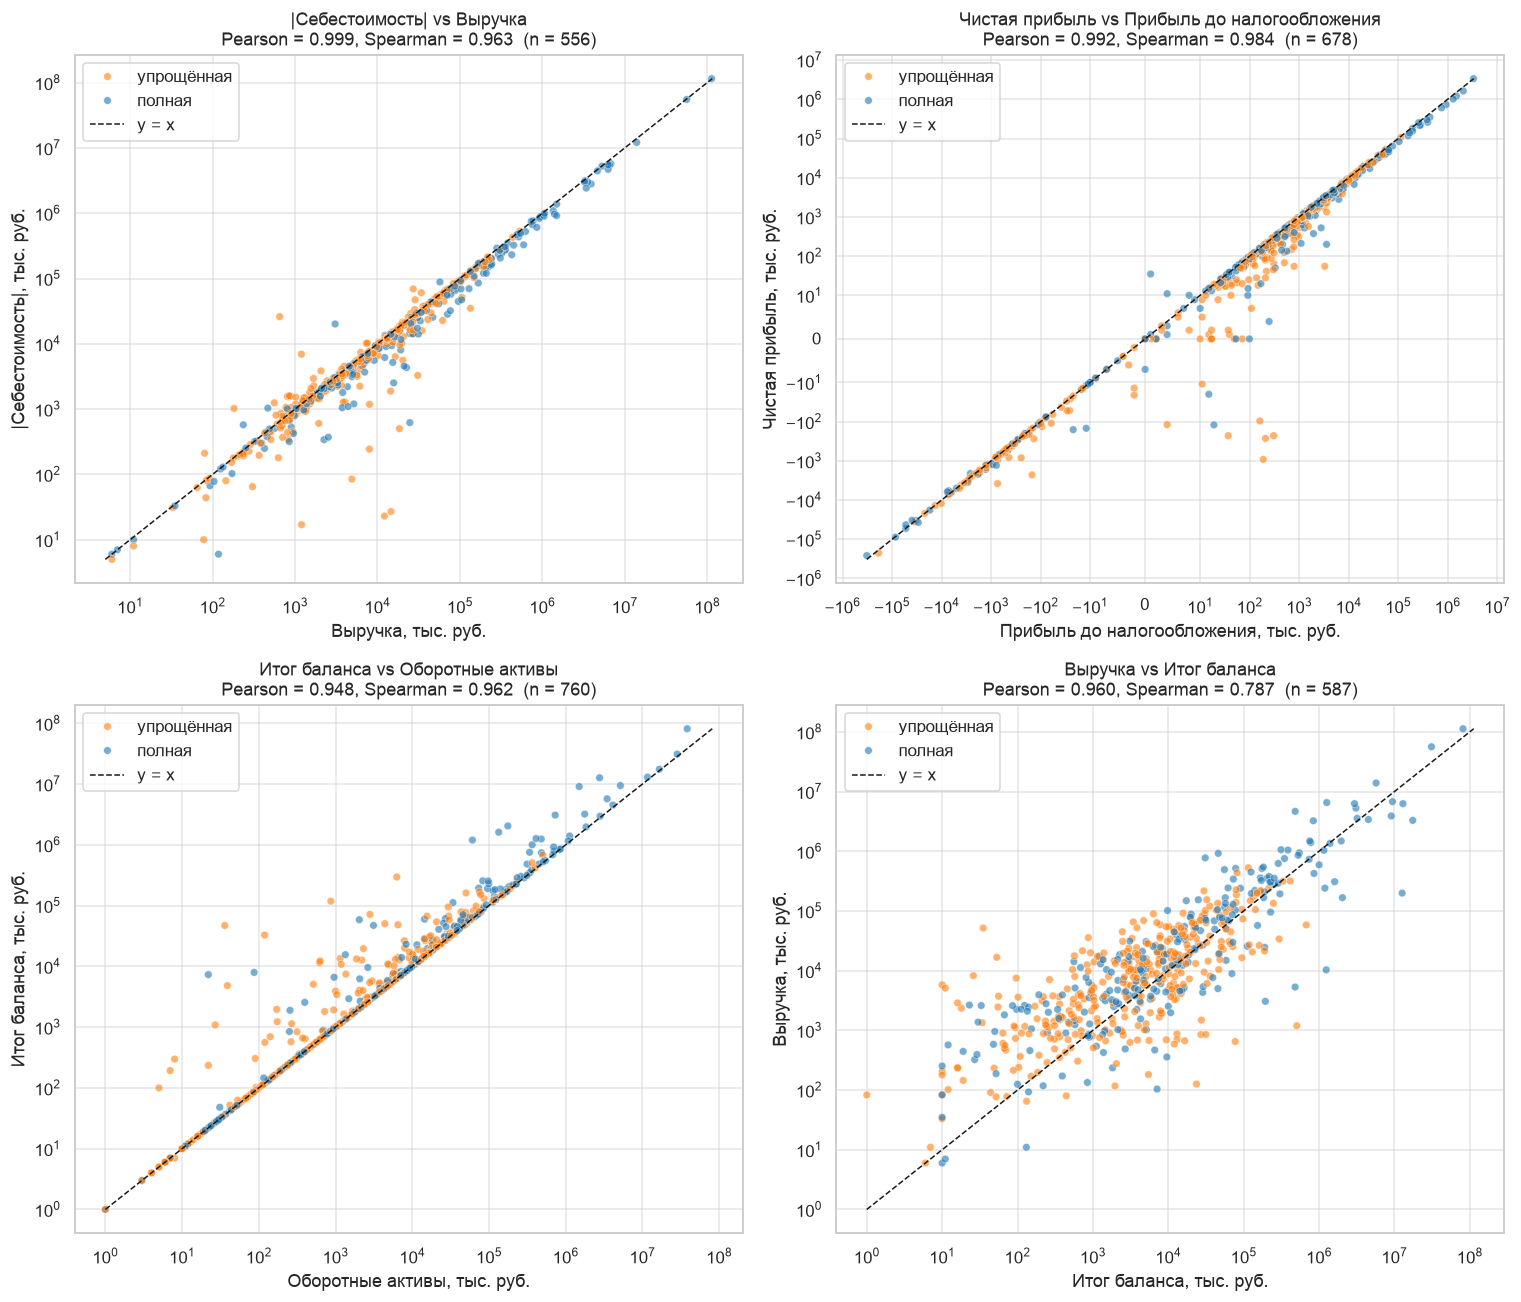

In [12]:
plot_df = df.copy()
plot_df["cost_abs"] = -plot_df["cost_of_sales"]
plot_df["форма отчётности"] = plot_df["simplified"].map({1.0: "упрощённая", 0.0: "полная"})

SCATTERS = [
    ("revenue", "cost_abs", "Выручка, тыс. руб.", "|Себестоимость|, тыс. руб.", "log"),
    ("pretax_profit", "net_profit", "Прибыль до налогообложения, тыс. руб.", "Чистая прибыль, тыс. руб.", "symlog"),
    ("current_assets", "total_assets", "Оборотные активы, тыс. руб.", "Итог баланса, тыс. руб.", "log"),
    ("total_assets", "revenue", "Итог баланса, тыс. руб.", "Выручка, тыс. руб.", "log"),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
for ax, (x, y, xl, yl, scale) in zip(axes.flat, SCATTERS):
    d = plot_df[[x, y, "форма отчётности"]].dropna()
    if scale == "log":
        d = d[(d[x] > 0) & (d[y] > 0)]
    sns.scatterplot(data=d, x=x, y=y, hue="форма отчётности", alpha=0.6, s=25, ax=ax,
                    palette={"упрощённая": "tab:orange", "полная": "tab:blue"})
    lim = [min(d[x].min(), d[y].min()), max(d[x].max(), d[y].max())]
    ax.plot(lim, lim, "k--", lw=1, label="y = x")
    if scale == "log":
        ax.set_xscale("log"); ax.set_yscale("log")
    else:
        ax.set_xscale("symlog", linthresh=10); ax.set_yscale("symlog", linthresh=10)
    r_p = df[[x if x != "cost_abs" else "cost_of_sales", y if y != "cost_abs" else "cost_of_sales"]].corr().iloc[0, 1]
    r_s = plot_df[[x, y]].corr(method="spearman").iloc[0, 1]
    ax.set_title(f"{yl.split(',')[0]} vs {xl.split(',')[0]}\nPearson = {abs(r_p):.3f}, Spearman = {r_s:.3f}  (n = {len(d)})")
    ax.set_xlabel(xl); ax.set_ylabel(yl)
    ax.grid(True, which="major", alpha=0.5)
    ax.legend(loc="upper left")

plt.tight_layout()
plt.show()

**Что видно на диаграммах**

* **Выручка и себестоимость.** Точки почти лежат на пунктире: у большинства компаний расходы почти равны выручке, то есть зарабатывают они немного. Точки выше пунктира — компании, которые продают себе в убыток, среди них и самое крупное предприятие выборки.
* **Прибыль до налогов и чистая прибыль.** Почти ровная линия чуть ниже пунктира: разница между ними — налог. Отдельные точки, где чистая прибыль больше доналоговой, — компании с налоговыми льготами или вычетами.
* **Оборотные активы и итог баланса.** Ни одна точка не лежит ниже пунктира: часть не может быть больше целого. Многие точки лежат прямо на пунктире — у этих компаний вообще нет зданий и оборудования, только деньги, товары и долги покупателей (торговля, услуги).
* **Итог баланса и выручка.** Связь есть, но точки сильно разбросаны: при одинаковом имуществе выручка может отличаться в 100–1000 раз. Это зависит от отрасли: магазин быстро оборачивает товар, а завод или арендодатель — медленно. Синие точки (полная отчётность) в среднем правее и выше оранжевых: это более крупные компании.

## 5. Выводы

1. **Несколько гигантов и много малых компаний.** Типичная компания получает около 6,6 млн ₽ выручки в год, но 5 крупнейших из 1000 дают 72 % всей выручки. Среднее значение здесь вводит в заблуждение, лучше смотреть на медиану.
2. **Одна компания может исказить корреляцию.** По Пирсону выручка и прибыль от продаж связаны отрицательно (−0,83), а по Спирмену — положительно (+0,65). Отрицательную связь создаёт одно крупное убыточное предприятие. Перед тем как делать выводы по корреляции, стоит сравнить оба коэффициента и посмотреть на график.
3. **Большинство сильных связей очевидны.** Выручка связана с себестоимостью, прибыль до налогов — с чистой прибылью. Это следует из того, как устроена отчётность, а не является открытием. Если строить на этих данных модель, из каждой такой пары лучше оставить один показатель.
4. **Ложная связь из-за выборки.** Связь возраста компании с долготой (0,71) появилась потому, что мы взяли первые 1000 строк файла, отсортированного по ИНН, и туда попали в основном два региона. Для честного анализа нужна случайная выборка.
5. **В данных есть ошибки и странности.** 17 % компаний не сдали отчёт. Есть отрицательные деньги и запасы, чего быть не может. У 85 компаний долгов больше, чем имущества, 54 компании ничего не продали, а у многих на балансе только минимальный уставный капитал. Похоже, это неработающие фирмы.